In [1]:
import pandas as pd
import numpy as np

In [2]:
import re
from pathlib import Path
import pandas as pd

FOLDER = Path("/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/AlgoGoneCrazy/visualization/data")   # แก้เป็น path ของคุณ

def to_name(stem: str) -> str:
    name = re.sub(r"\W+", "_", stem).strip("_").lower()
    if name and name[0].isdigit():   # ชื่อตัวแปรขึ้นต้นด้วยตัวเลขไม่ได้
        name = "df_" + name
    return f"{name}_df"

dfs = {}
for f in sorted(FOLDER.glob("*.csv")):
    dfs[to_name(f.stem)] = pd.read_csv(f)
    print(f"{f.name:30} -> {to_name(f.stem):25} {len(dfs[to_name(f.stem)]):,} rows")

backfilled_market_bars_30m.csv -> backfilled_market_bars_30m_df 20 rows
incomplete_market_bars_30m.csv -> incomplete_market_bars_30m_df 20 rows
market_bars_30m.csv            -> market_bars_30m_df        3,939 rows
market_bars_30m_with_backfill.csv -> market_bars_30m_with_backfill_df 3,959 rows
market_bars_5m.csv             -> market_bars_5m_df         23,739 rows
market_session_coverage.csv    -> market_session_coverage_df 180 rows
missing_market_bars_5m.csv     -> missing_market_bars_5m_df 20 rows
rejected_market_bars_5m.csv    -> rejected_market_bars_5m_df 620 rows
unresolved_market_bars_30m.csv -> unresolved_market_bars_30m_df 0 rows


In [3]:
pd.set_option("display.max_columns", None)

In [4]:
dfs['market_bars_30m_df']['source'].value_counts()

binance_spot     2831
yahoo_finance    1108
Name: source, dtype: int64

In [5]:
dfs['market_bars_30m_df']['%change'] = dfs['market_bars_30m_df'].groupby('instrument_id')['close'].pct_change() * 100

In [6]:
dfs['market_bars_30m_df']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 04:30:00+00:00,2026-07-01 05:00:00+00:00,2026-07-01,59274.000,59457.000,59200.000,59339.990,59339.990,325.49941,BTC,1.931938e+07,USDT,63774.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,59339.990,59376.480,59154.020,59174.000,59174.000,319.60119,BTC,1.894897e+07,USDT,55643.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.279727
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,59174.000,59204.430,59126.420,59154.330,59154.330,112.70368,BTC,6.668226e+06,USDT,31850.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.033241
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,59154.330,59156.000,58692.000,58791.160,58791.160,334.28162,BTC,1.969248e+07,USDT,78534.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.613936
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,58791.160,58834.850,58534.310,58755.800,58755.800,459.85239,BTC,2.698495e+07,USDT,71378.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.060145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128


# Plotting

## Closing Price

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Fixed categorical color slots (blue, orange, aqua, ...) assigned by product
# in a stable order, so a given product always gets the same color across plots.
PRODUCT_COLORS = {
    'btc_usdt': '#2a78d6',
    'spy_usd': '#eb6834',
    'sti_es3_sgd': '#1baf7a',
}


def plot_series(
    df,
    instrument_id,
    label=None,
    color=None,
    time_col='bar_close_time_utc',
    val_col='close',
    figsize=(11, 4),
):
    """Plot the closing price over time for a single product/instrument."""
    sub = df[df['instrument_id'] == instrument_id].copy()
    sub[time_col] = pd.to_datetime(sub[time_col])
    sub = sub.sort_values(time_col)

    label = label or instrument_id
    color = color or PRODUCT_COLORS.get(instrument_id, '#2a78d6')

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('#fcfcfb')
    ax.set_facecolor('#fcfcfb')

    ax.plot(sub[time_col], sub[val_col], color=color, linewidth=1.5)
    ax.set_title(f'{label} — {val_col.capitalize()} Over Time', loc='left', fontsize=12, color='#0b0b0b')
    ax.set_ylabel(val_col.capitalize(), color='#52514e', fontsize=9)
    ax.grid(True, color='#e1e0d9', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#c3c2b7')
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(colors='#898781', labelsize=9)

    # Let matplotlib pick a sparse set of date ticks rather than labeling every bar.
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    fig.tight_layout()
    plt.show()
    return fig, ax

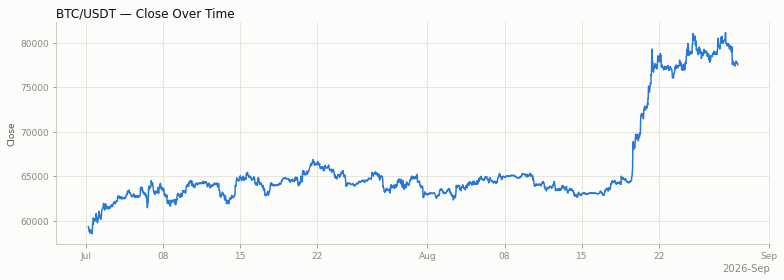

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd14999fe20>)

In [8]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='close')

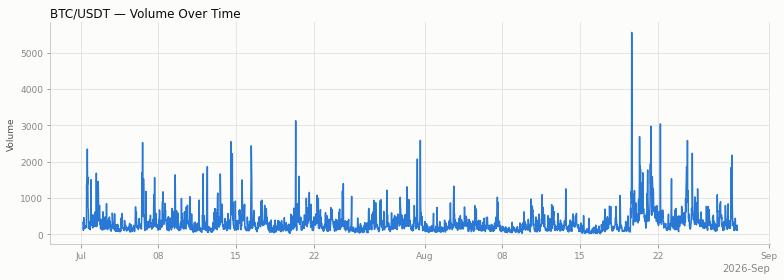

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd149f2db80>)

In [9]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='volume')

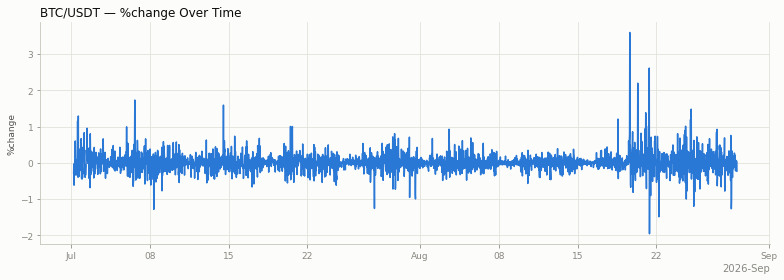

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd149fb7ee0>)

In [10]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='%change')

In [11]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt']['%change'].describe()

count    2830.000000
mean        0.009789
std         0.265419
min        -1.951777
25%        -0.103961
50%         0.000103
75%         0.112265
max         3.593090
Name: %change, dtype: float64

In [12]:
dfs['market_bars_30m_df']['instrument_id'].value_counts()

btc_usdt       2831
sti_es3_sgd     562
spy_usd         546
Name: instrument_id, dtype: int64

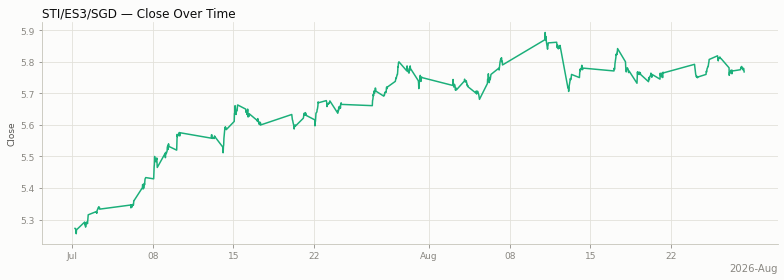

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd139f415e0>)

In [13]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='close')

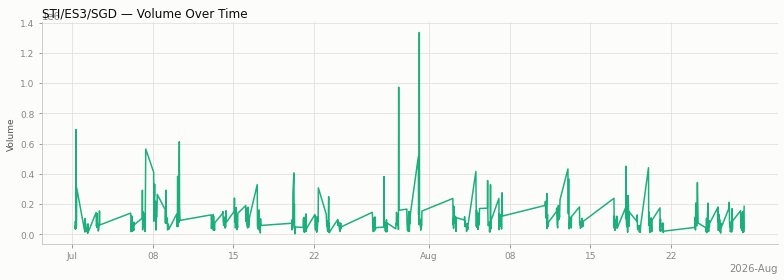

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd128d333d0>)

In [14]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='volume')

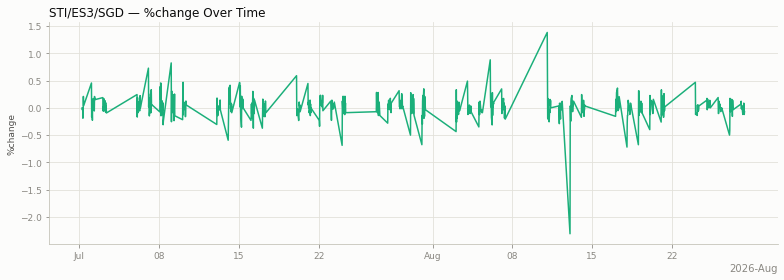

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd149f58610>)

In [15]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='%change')

In [16]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'sti_es3_sgd']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change
3377,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,5.279,5.279,5.269,5.272,5.272,82965.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN
3378,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,5.272,5.272,5.270,5.272,5.272,34034.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3379,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,5.272,5.276,5.267,5.270,5.270,57668.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.037934
3380,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,5.270,5.275,5.265,5.270,5.270,35588.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3381,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 07:00:00+00:00,2026-07-01 07:30:00+00:00,2026-07-01,5.270,5.273,5.258,5.260,5.260,692692.0,units,NaN,SGD,NaN,True,6,6,1.0,warning,zero_volume,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.189749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128


In [17]:
def add_rsi(df, price_col='close', period=14, group_col='instrument_id', time_col='bar_close_time_utc'):
    """Add a Wilder's RSI column (momentum, 0-100) to df, computed per instrument."""
    df = df.sort_values([group_col, time_col])

    delta = df.groupby(group_col)[price_col].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.groupby(df[group_col]).transform(
        lambda s: s.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    )
    avg_loss = loss.groupby(df[group_col]).transform(
        lambda s: s.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    )

    rs = avg_gain / avg_loss
    df['rsi'] = 100 - (100 / (1 + rs))
    return df

In [18]:
dfs['market_bars_30m_df'] = add_rsi(dfs['market_bars_30m_df'])
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt']['rsi'].describe()

count    2817.000000
mean       51.832637
std        11.863776
min        16.424010
25%        43.822558
50%        51.701354
75%        59.365236
max        95.776653
Name: rsi, dtype: float64

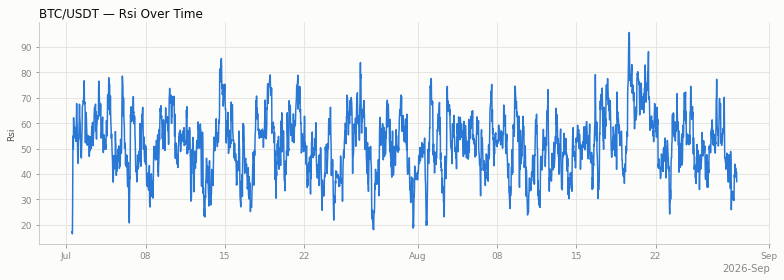

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7fd13a08fd30>)

In [19]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='rsi')

In [20]:
dfs['market_bars_30m_df']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change,rsi
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 04:30:00+00:00,2026-07-01 05:00:00+00:00,2026-07-01,59274.000,59457.000,59200.000,59339.990,59339.990,325.49941,BTC,1.931938e+07,USDT,63774.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN,NaN
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,59339.990,59376.480,59154.020,59174.000,59174.000,319.60119,BTC,1.894897e+07,USDT,55643.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.279727,NaN
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,59174.000,59204.430,59126.420,59154.330,59154.330,112.70368,BTC,6.668226e+06,USDT,31850.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.033241,NaN
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,59154.330,59156.000,58692.000,58791.160,58791.160,334.28162,BTC,1.969248e+07,USDT,78534.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.613936,NaN
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,58791.160,58834.850,58534.310,58755.800,58755.800,459.85239,BTC,2.698495e+07,USDT,71378.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.060145,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315,44.267435
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589,49.030716
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000,49.030716
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128,43.055510


## RSI Momentum Check: Forward Return by Regime

For each bar, look `n` steps ahead and measure the % price change. Compare that
forward return when RSI was oversold (< 35) vs overbought (> 65) at the starting
bar.

In [21]:
def add_forward_return(df, periods=10, price_col='close', group_col='instrument_id', time_col='bar_close_time_utc'):
    """Add a forward % return column: change from t to t+periods bars ahead, per instrument."""
    df = df.sort_values([group_col, time_col])
    df[f'fwd_return_{periods}'] = df.groupby(group_col)[price_col].transform(
        lambda s: (s.shift(-periods) - s) / s * 100
    )
    return df


for i in range(1, 11):
    dfs['market_bars_30m_df'] = add_forward_return(dfs['market_bars_30m_df'], periods=i)

In [22]:
dfs['market_bars_30m_df']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change,rsi,fwd_return_1,fwd_return_2,fwd_return_3,fwd_return_4,fwd_return_5,fwd_return_6,fwd_return_7,fwd_return_8,fwd_return_9,fwd_return_10
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 04:30:00+00:00,2026-07-01 05:00:00+00:00,2026-07-01,59274.000,59457.000,59200.000,59339.990,59339.990,325.49941,BTC,1.931938e+07,USDT,63774.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN,NaN,-0.279727,-0.312875,-0.924891,-0.984479,-1.011106,-0.962825,-1.213313,-0.616785,-0.761695,-0.666397
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,59339.990,59376.480,59154.020,59174.000,59174.000,319.60119,BTC,1.894897e+07,USDT,55643.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.279727,NaN,-0.033241,-0.646973,-0.706729,-0.733430,-0.685014,-0.936205,-0.338003,-0.483320,-0.387755,-0.724626
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,59174.000,59204.430,59126.420,59154.330,59154.330,112.70368,BTC,6.668226e+06,USDT,31850.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.033241,NaN,-0.613936,-0.673712,-0.700422,-0.651989,-0.903264,-0.304864,-0.450229,-0.354632,-0.691615,-0.835695
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,59154.330,59156.000,58692.000,58791.160,58791.160,334.28162,BTC,1.969248e+07,USDT,78534.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.613936,NaN,-0.060145,-0.087020,-0.038288,-0.291115,0.310982,0.164719,0.260907,-0.078158,-0.223129,-0.158068
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,58791.160,58834.850,58534.310,58755.800,58755.800,459.85239,BTC,2.698495e+07,USDT,71378.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.060145,NaN,-0.026891,0.021870,-0.231109,0.371351,0.224999,0.321245,-0.018024,-0.163082,-0.097982,-0.227671
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315,44.267435,0.086589,0.086589,-0.034644,-0.103915,NaN,NaN,NaN,NaN,NaN,NaN
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589,49.030716,0.000000,-0.121128,-0.190339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000,49.030716,-0.121128,-0.190339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3937,sti_es

In [23]:
def rsi_regime_stats(df, low=35, high=65, periods=10, rsi_col='rsi', group_col='instrument_id'):
    """Compare forward returns following an oversold (rsi < low) vs overbought (rsi > high) reading."""
    ret_col = f'fwd_return_{periods}'
    oversold = df.loc[df[rsi_col] < low, ret_col].dropna()
    overbought = df.loc[df[rsi_col] > high, ret_col].dropna()

    summary = pd.DataFrame({
        f'oversold (rsi<{low})': oversold.describe(),
        f'overbought (rsi>{high})': overbought.describe(),
    })

    by_instrument = df.assign(
        regime=np.select(
            [df[rsi_col] < low, df[rsi_col] > high],
            ['oversold', 'overbought'],
            default=None,
        )
    ).dropna(subset=['regime', ret_col]).groupby([group_col, 'regime'])[ret_col].agg(['count', 'mean', 'median', 'std'])

    return summary, by_instrument, oversold, overbought


summary, by_instrument, oversold, overbought = rsi_regime_stats(dfs['market_bars_30m_df'], low=35, high=65, periods=1)
summary

,oversold (rsi<35),overbought (rsi>65)
count,299.000000,626.000000
mean,0.036112,0.018884
std,0.248223,0.317716
min,-1.022110,-1.951777
25%,-0.080676,-0.110825
50%,0.030420,0.008838
75%,0.158505,0.120017
max,1.245308,3.593090


In [24]:
by_instrument

count      mean    median       std
instrument_id regime                                         
btc_usdt      overbought    386  0.023384  0.007872  0.377878
              oversold      223  0.026702  0.026648  0.254290
spy_usd       overbought     80  0.002776 -0.005301  0.177309
              oversold       55  0.044862  0.030420  0.229411
sti_es3_sgd   overbought    160  0.016083  0.017692  0.187693
              oversold       21  0.113113  0.105237  0.225325

In [25]:
summary, by_instrument, oversold, overbought = rsi_regime_stats(dfs['market_bars_30m_df'], low=35, high=65, periods=2)
summary

,oversold (rsi<35),overbought (rsi>65)
count,299.000000,626.000000
mean,0.061221,0.045445
std,0.345315,0.457749
min,-1.168030,-1.699916
25%,-0.098042,-0.145088
50%,0.048186,0.021097
75%,0.245350,0.180960
max,1.639994,4.404465


In [26]:
by_instrument

count      mean    median       std
instrument_id regime                                         
btc_usdt      overbought    386  0.050369 -0.001802  0.542171
              oversold      223  0.044965  0.045322  0.357223
spy_usd       overbought     80  0.019222  0.050965  0.284789
              oversold       55  0.060515  0.016162  0.281704
sti_es3_sgd   overbought    160  0.046678  0.051967  0.266784
              oversold       21  0.235695  0.191074  0.333303

In [27]:
summary, by_instrument, oversold, overbought = rsi_regime_stats(dfs['market_bars_30m_df'], low=35, high=65, periods=3)
summary

,oversold (rsi<35),overbought (rsi>65)
count,299.000000,626.000000
mean,0.081073,0.073400
std,0.432890,0.577377
min,-1.743984,-1.677420
25%,-0.139340,-0.176479
50%,0.087167,0.030140
75%,0.309236,0.244341
max,2.118248,5.044859


In [28]:
by_instrument

count      mean    median       std
instrument_id regime                                         
btc_usdt      overbought    386  0.077193  0.003042  0.683259
              oversold      223  0.059922  0.079509  0.459181
spy_usd       overbought     80  0.032088  0.052841  0.354277
              oversold       55  0.079396  0.065130  0.298110
sti_es3_sgd   overbought    160  0.084906  0.086060  0.341466
              oversold       21  0.310073  0.140398  0.389570

In [29]:
summary, by_instrument, oversold, overbought = rsi_regime_stats(dfs['market_bars_30m_df'], low=35, high=65, periods=4)
summary

,oversold (rsi<35),overbought (rsi>65)
count,299.000000,626.000000
mean,0.122927,0.096553
std,0.527988,0.685088
min,-1.793097,-1.857175
25%,-0.110807,-0.201607
50%,0.121443,0.022501
75%,0.383017,0.284116
max,2.878131,5.448030


In [30]:
by_instrument

count      mean    median       std
instrument_id regime                                         
btc_usdt      overbought    386  0.102027 -0.001934  0.813222
              oversold      223  0.092205  0.099843  0.568735
spy_usd       overbought     80  0.040875  0.070113  0.414843
              oversold       55  0.121041  0.124731  0.309769
sti_es3_sgd   overbought    160  0.111185  0.098549  0.395252
              oversold       21  0.454110  0.349467  0.422516

## MACD

In [31]:
def add_macd(df, price_col='close', fast=12, slow=26, signal=9, group_col='instrument_id', time_col='bar_close_time_utc'):
    """Add MACD line, signal line, and histogram columns, computed per instrument."""
    df = df.sort_values([group_col, time_col])

    ema_fast = df.groupby(group_col)[price_col].transform(lambda s: s.ewm(span=fast, adjust=False).mean())
    ema_slow = df.groupby(group_col)[price_col].transform(lambda s: s.ewm(span=slow, adjust=False).mean())
    df['macd'] = ema_fast - ema_slow
    df['macd_signal'] = df.groupby(group_col)['macd'].transform(lambda s: s.ewm(span=signal, adjust=False).mean())
    df['macd_hist'] = df['macd'] - df['macd_signal']
    return df


dfs['market_bars_30m_df'] = add_macd(dfs['market_bars_30m_df'])
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt'][['macd', 'macd_signal', 'macd_hist']].describe()

,macd,macd_signal,macd_hist
count,2831.000000,2831.000000,2831.000000
mean,46.517597,46.969676,-0.452079
std,220.081429,209.561660,58.872840
min,-575.863569,-530.020288,-205.833993
25%,-66.112467,-61.130875,-31.665589
50%,25.323295,25.250127,-0.518529
75%,126.307275,121.638437,27.100416
max,1293.988842,1153.682744,486.771869


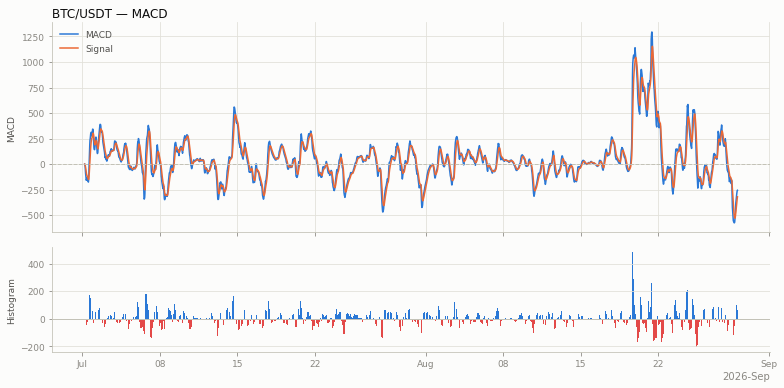

(<Figure size 792x396 with 2 Axes>,
 (<matplotlib.axes._subplots.AxesSubplot at 0x7faf30152520>,
  <matplotlib.axes._subplots.AxesSubplot at 0x7faf60727550>))

In [74]:
def plot_macd(df, instrument_id, label=None, time_col='bar_close_time_utc', figsize=(11, 5.5)):
    """Plot MACD line, signal line, and histogram for a single product/instrument."""
    sub = df[df['instrument_id'] == instrument_id].copy()
    sub[time_col] = pd.to_datetime(sub[time_col])
    sub = sub.sort_values(time_col)

    label = label or instrument_id

    fig, (ax_line, ax_hist) = plt.subplots(
        2, 1, figsize=figsize, sharex=True, gridspec_kw={'height_ratios': [2, 1]}
    )
    fig.patch.set_facecolor('#fcfcfb')

    # MACD line + signal line: two categorical series, identity carried by hue + legend.
    ax_line.set_facecolor('#fcfcfb')
    ax_line.plot(sub[time_col], sub['macd'], color='#2a78d6', linewidth=1.5, label='MACD')
    ax_line.plot(sub[time_col], sub['macd_signal'], color='#eb6834', linewidth=1.5, label='Signal')
    ax_line.axhline(0, color='#c3c2b7', linewidth=1, linestyle='--')
    ax_line.set_title(f'{label} — MACD', loc='left', fontsize=12, color='#0b0b0b')
    ax_line.set_ylabel('MACD', color='#52514e', fontsize=9)
    ax_line.grid(True, color='#e1e0d9', linewidth=0.8)
    legend = ax_line.legend(loc='upper left', frameon=False, fontsize=9)
    for text in legend.get_texts():
        text.set_color('#52514e')
    ax_line.spines['top'].set_visible(False)
    ax_line.spines['right'].set_visible(False)
    ax_line.spines['left'].set_color('#c3c2b7')
    ax_line.spines['bottom'].set_color('#c3c2b7')
    ax_line.tick_params(colors='#898781', labelsize=9)

    # Histogram: diverging blue/red by sign (bullish vs bearish momentum), same
    # polarity encoding used for the RSI oversold/overbought comparison above.
    ax_hist.set_facecolor('#fcfcfb')
    hist_colors = np.where(sub['macd_hist'] >= 0, '#2a78d6', '#e34948')
    median_gap_days = (sub[time_col].diff().median()) / pd.Timedelta(days=1)
    ax_hist.bar(sub[time_col], sub['macd_hist'], color=hist_colors, width=median_gap_days * 0.8, linewidth=0)
    ax_hist.axhline(0, color='#c3c2b7', linewidth=1)
    ax_hist.set_ylabel('Histogram', color='#52514e', fontsize=9)
    ax_hist.grid(True, axis='y', color='#e1e0d9', linewidth=0.8)
    ax_hist.spines['top'].set_visible(False)
    ax_hist.spines['right'].set_visible(False)
    ax_hist.spines['left'].set_color('#c3c2b7')
    ax_hist.spines['bottom'].set_color('#c3c2b7')
    ax_hist.tick_params(colors='#898781', labelsize=9)

    # Sparse date ticks on the shared bottom axis rather than labeling every bar.
    locator = mdates.AutoDateLocator()
    ax_hist.xaxis.set_major_locator(locator)
    ax_hist.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    fig.tight_layout()
    plt.show()
    return fig, (ax_line, ax_hist)


plot_macd(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT')

In [70]:
latest_100 = dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt'].tail(100)

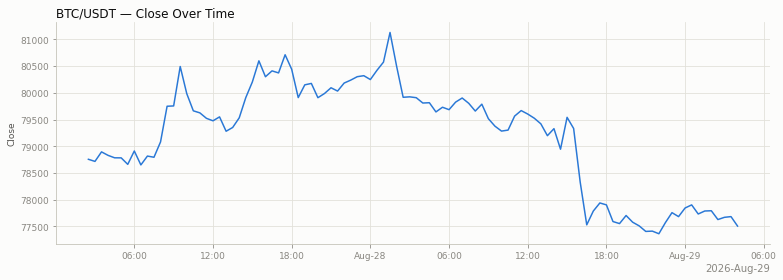

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7faf70d40820>)

In [72]:
plot_series(latest_100, 'btc_usdt', label='BTC/USDT', val_col='close')

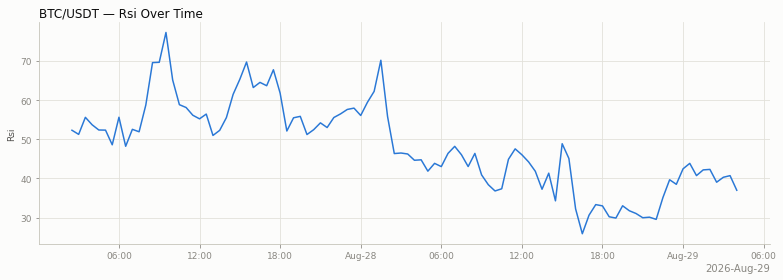

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7faf80c2b160>)

In [76]:
plot_series(latest_100, 'btc_usdt', label='BTC/USDT', val_col='rsi')

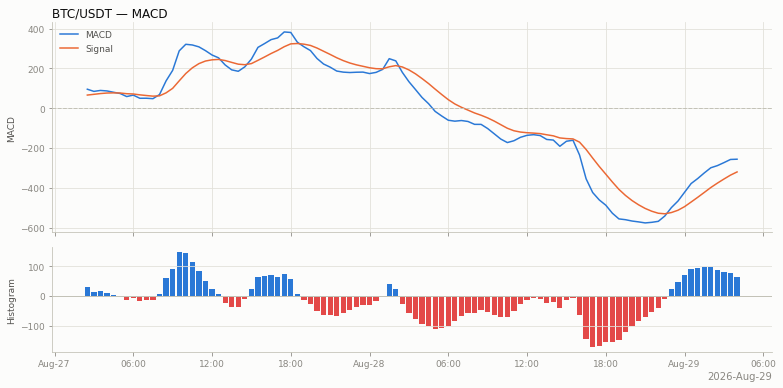

(<Figure size 792x396 with 2 Axes>,
 (<matplotlib.axes._subplots.AxesSubplot at 0x7faf3014ccd0>,
  <matplotlib.axes._subplots.AxesSubplot at 0x7faf4248c850>))

In [75]:
plot_macd(latest_100, 'btc_usdt', label='BTC/USDT')

In [80]:
random_100 = dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt'][-500:-400]

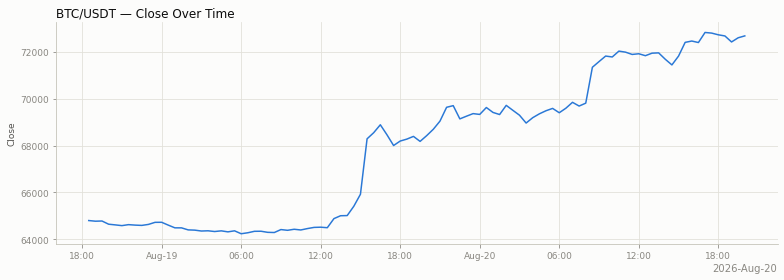

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7faf71a84be0>)

In [82]:
plot_series(random_100, 'btc_usdt', label='BTC/USDT', val_col='close')

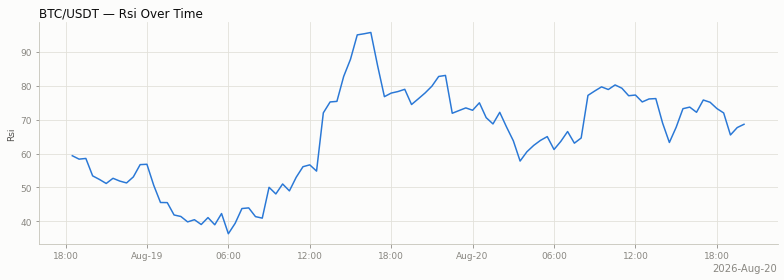

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7faf3833e670>)

In [84]:
plot_series(random_100, 'btc_usdt', label='BTC/USDT', val_col='rsi')

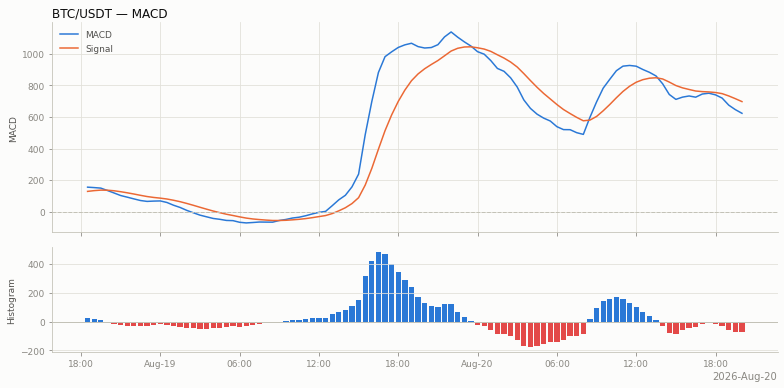

(<Figure size 792x396 with 2 Axes>,
 (<matplotlib.axes._subplots.AxesSubplot at 0x7faf80f16760>,
  <matplotlib.axes._subplots.AxesSubplot at 0x7faf42bcabb0>))

In [85]:
plot_macd(random_100, 'btc_usdt', label='BTC/USDT')